In [1]:
from collections import defaultdict
from math import log2
import re
import heapq
import gc
from wordcloud import WordCloud
import matplotlib.pyplot as plt

In [2]:
with open("/kaggle/input/datasets/yunuskedir/gpac-corpus/GPAC.txt") as f:
    text = f.read()
text = text[:len(text) // 10]
print(f"Corpus is {len(text)} characters long.")

Corpus is 42439773 characters long.


In [3]:
### Preprocessing functions

def normalize_phonetically_similar_characters(text):
    print("Normalizing phonetically similar characters in the Amharic Langauge (ሐ -> ሀ, ኀ -> ሀ, ሠ -> ሰ, ፀ -> ጸ)...")
    replacement_map = {
      "ሐሑሒሓሔሕሖ": "ሀሁሂሃሄህሆ",
      "ኀኁኂኃኄኅኆ": "ሀሁሂሃሄህሆ",
      "ሠሡሢሣሤሥሦሧ": "ሰሱሲሳሴስሶሷ",
      "ፀፁፂፃፄፅፆ": "ጸጹጺጻጼጽጾ"
    }
    for chars, replacements in replacement_map.items():
        for i in range(len(chars)):
            text = text.replace(chars[i], replacements[i])
    return text

def remove_extra_whitespace(text):
    print("Removing any extra whitespace between words...")
    return re.sub(r"\s+", " ", text)

def remove_punctuation(text):
    print("Removing punctuation to decrease noise...")
    punctuations = ["፣", "፤", "(", ")", "፦", "፡"]
    for punc in punctuations:
        text = text.replace(punc, "")
    return text

def add_delimiter_tags(text):
    print("Adding sentence delimiter tags (<s></s>)...")
    text = "<s> " + text
    sentence_delimiters = ["፡፡", "።", "!", "?"]
    for delimiter in sentence_delimiters:
        text = text.replace(delimiter, f" {delimiter} </s> <s> ")
    
    text = " ".join(text.split())
    
    if text.endswith("<s>"):
        text = text[:-3].strip()

    return text

def remove_common_stopwords(text):
    print("Removing common stopwords...")
    sentence_delimiters = ["፡፡", "።", "!", "?"]
    for delimiter in sentence_delimiters:
        text = text.replace(delimiter, "")
    return text

def preprocess_corpus(corpus_content: str, remove_stopwords: bool = False):
    print("Initialzing corpus preprocessing...")
    print("Trimming any extra whitespace...")
    corpus_content = corpus_content.strip()
    corpus_content = normalize_phonetically_similar_characters(corpus_content)
    corpus_content = remove_extra_whitespace(corpus_content)
    corpus_content = remove_punctuation(corpus_content)
    if remove_stopwords:
        corpus_content = remove_common_stopwords(corpus_content)
    else:
        corpus_content = add_delimiter_tags(corpus_content)
    print("Preprocessing finished...")
    return corpus_content

In [4]:
def get_corpus_words(corpus):
    words = corpus.split()
    return words

In [5]:
sanitized_corpus = preprocess_corpus(text, remove_stopwords=True)
del text
corpus_words = get_corpus_words(sanitized_corpus)
print(f"Corpus contains {len(corpus_words)} words, and {len(set(corpus_words))} unique words.")
del sanitized_corpus
gc.collect()
split_idx = int(len(corpus_words) * 0.8)
train_data = corpus_words[:split_idx]
test_data = corpus_words[split_idx:]

Initialzing corpus preprocessing...
Trimming any extra whitespace...
Normalizing phonetically similar characters in the Amharic Langauge (ሐ -> ሀ, ኀ -> ሀ, ሠ -> ሰ, ፀ -> ጸ)...
Removing any extra whitespace between words...
Removing punctuation to decrease noise...
Removing common stopwords...
Preprocessing finished...
Corpus contains 7882376 words, and 671222 unique words.


In [6]:
class NGramModel:
    def __init__(self, words: list[str], n: int = 2):
        if n < 1 or n > 5:
            raise ValueError(f"n must be a value between 1 and 5: {n} was given")
        print(f"Initializing NGramModel instance of order {n}...")
        self.n = n
        if n == 1:
            self.ngram_counts = defaultdict(int)
            self.__build_counts(words)
            self.words_count = sum(self.ngram_counts.values())
        else:
            self.ngram_counts = defaultdict(lambda: defaultdict(int))
            self.__build_counts(words)

        del words
        print("Finished initializing NGramModel instance. Model is ready to use.")

    def __build_counts(self, words: list[str]):
        if self.n == 1:
            sentence_delimiters = ["፡፡", "።", "!", "?", "<s>", "</s>"]
            for word in words:
                if word not in sentence_delimiters:
                    self.ngram_counts[(word,)] += 1
        else:
            for i in range(self.n - 1, len(words)):
                sequence = tuple(words[i - self.n + 1:i + 1])
                if "</s>" in sequence:
                    i += sequence.index("</s>")
                    continue
                prev_sequence = sequence[:-1]
                self.ngram_counts[prev_sequence][(sequence[-1],)] += 1

    def get_k_most_frequent_sequences(self, k=10):
        if self.n == 1:
            top_tuples = heapq.nlargest(k, self.ngram_counts, key=lambda x: self.ngram_counts[x])
            return [(t[0], self.ngram_counts[t]) for t in top_tuples]

        else:
            top_tuples = heapq.nlargest(k, ((outer_t, inner_t, count) for outer_t, inner in self.ngram_counts.items() for inner_t, count in inner.items()), key=lambda x: x[2])
            return [(f"{" ".join(t[0])} {t[1][0]}", t[2]) for t in top_tuples]

    def draw_wordcloud(self, title=""):
        if self.n == 1:
            freq_dict = { t[0]: count for t, count in self.ngram_counts.items() }
        else:
            freq_dict = { f"{" ".join(outer_t)} {inner_t[0]}": count for outer_t, inner in self.ngram_counts.items() for inner_t, count in inner.items() }

        wc = WordCloud(
            width=800,
            height=400,
            background_color="white",
            font_path="/kaggle/input/datasets/yunuskedir/hiburmono-font/HiburMono-Regular.ttf"
        ).generate_from_frequencies(freq_dict)
        plt.figure(figsize=(12, 6))
        plt.imshow(wc, interpolation="bilinear")
        plt.axis("off")
        plt.title(title if title else f"Word Cloud for NGram of order {self.n}")
        plt.show()


    def get_word_probability(self, word: str, history: str = ""):
        if not word:
            print("Please provide a non-empty word.")
            return None
        if self.n == 1:
            return self.ngram_counts.get((word,), 0) / self.words_count

        history_words = tuple(history.split()[-self.n+1:])
        if len(history_words) < self.n - 1:
            print(f"For order n={self.n}, history must contain at least {self.n - 1} words long: {len(history_words)} words given.")
            return 0.0
        count_history = sum(self.ngram_counts[history_words].values())
        if count_history == 0:
            return 0.0

        count_together = self.ngram_counts[history_words][(word,)]
        return count_together / count_history

    def get_k_most_probable_words(self, history: str = "", prefix: str = "", k: int = 10):
        if k < 1:
            print(f"Please provide a valid k value: {k} was given.")
            return []
        if self.n == 1:
            valid_sequences = {t: count for t, count in self.ngram_count.items() if t[0].startswith(prefix)} if prefix else self.ngram_counts
        else:
            history_words = tuple(history.split()[-self.n + 1:])
            if len(history_words) < self.n - 1:
                print(f"For order n={self.n}, history must contain at least {self.n - 1} words: {len(history_words)} words given.")
                return []
            if self.ngram_counts.get(history_words, None) == None:
                return []
            valid_sequences = { t: count for t, count in self.ngram_counts[history_words].items() if t[0].startswith(prefix) } if prefix else self.ngram_counts[history_words]
        count_history = sum(valid_sequences.values())
        if count_history == 0:
            return []
        top_tuples = heapq.nlargest(k, valid_sequences, key=lambda x: valid_sequences[x])
        return [(t[0], valid_sequences[t] / count_history) for t in top_tuples]

    def calculate_perplexity(self, test_data):
        log_prob_sum = 0
        word_count = 0
        for i in range(self.n - 1, len(test_data)):
            sequence = test_data[i-self.n+1:i+1]
            if "</s>" in sequence:
                i += sequence.index("</s>")
                continue
            if self.n == 1 or self.ngram_counts[tuple(sequence[:-1])]:
                history = " ".join(sequence[:-1])     
                prob = self.get_word_probability(sequence[-1], history)
                if prob > 0:
                    log_prob_sum += log2(prob)
                word_count += 1
        return 2 ** (-1 * (log_prob_sum / word_count))

    def calculate_accuracy(self, test_data):
        total_count = 0
        correct_count = 0
        for i in range(self.n-1, len(test_data)):
            sequence = test_data[i-self.n+1:i+1]
            if "</s>" in sequence:
                i += sequence.index("</s>")
                continue
            context = " ".join(sequence[:-1])
            correct_word = sequence[-1]
            top_10_predictions = self.get_k_most_probable_words(history=context)
            top_10_words = list(map(lambda tupl: tupl[0], top_10_predictions))
            if correct_word in top_10_words:
                correct_count += (10 - top_10_words.index(correct_word)) / 10
            total_count += 1
        return (correct_count / (total_count if total_count else 1)) * 100

# **UNIGRAM (NGRAM of order 1)**

In [7]:
# UNIGRAM (NGRAM OF ORDER 1)
unigram = NGramModel(corpus_words, 1)

Initializing NGramModel instance of order 1...
Finished initializing NGramModel instance. Model is ready to use.


In [8]:
# UNIGRAM TOP 10 MOST PROBABLE/FREQUENT SEQUENCES/WORDS
unigram.get_k_most_frequent_sequences()

[('ነው', 148607),
 ('ላይ', 75110),
 ('ውስጥ', 36020),
 ('ወደ', 35788),
 ('ግን', 35686),
 ('ነበር', 34000),
 ('እና', 31023),
 ('ነገር', 28788),
 ('ጋር', 28624),
 ('ጊዜ', 23788)]

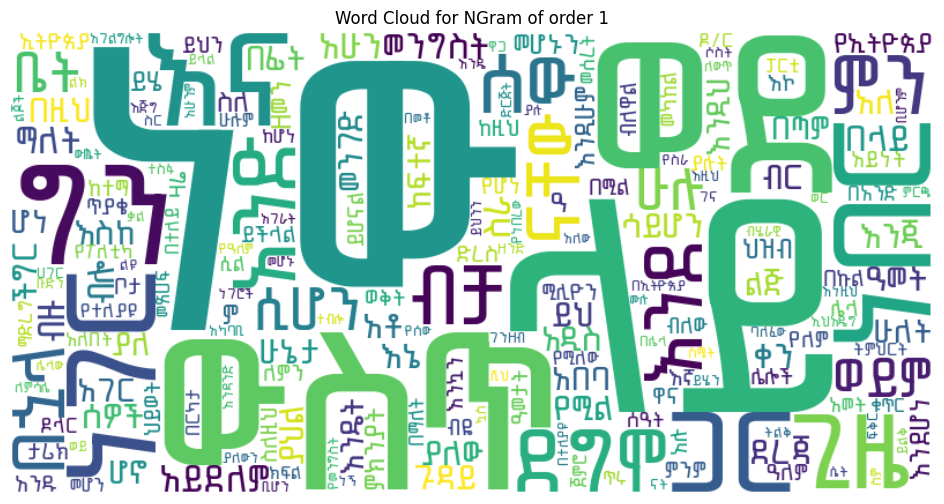

In [9]:
# DRAW UNIGRAM WORDCLOUD
unigram.draw_wordcloud()

In [10]:
# UNIGRAM SENTENCE GENERATION
sentence = "የተጐናጸፉ ሰዎች የህይወት ታሪክ"
for i in range(15):
    top_suggestions = unigram.get_k_most_probable_words(sentence, k=1)
    if len(top_suggestions) > 0:
        sentence = sentence + " " + top_suggestions[0][0]
print(sentence)

የተጐናጸፉ ሰዎች የህይወት ታሪክ ነው ነው ነው ነው ነው ነው ነው ነው ነው ነው ነው ነው ነው ነው ነው


Since unigram models don't consider context, the most frequent word in the corpus is the top suggestion every time.

In [11]:
# REMOVE UNNEEDED MODEL AND CLEAN UP
del unigram
gc.collect()

2455

**INTRINSIC AND EXTRINSIC EVALUATION OF UNIGRAM**

In [12]:
trained_unigram = NGramModel(train_data, n=1)

# UNIGRAM PERPLEXITY CALCULATION (INTRINSIC EVALUATION)
perplexity = trained_unigram.calculate_perplexity(test_data)
print(f"Unigram gets a perplexity score of {perplexity}")

# UNIGRAM ACCURACY CALCULATION (EXTRINSIC EVALUATION)
accuracy = trained_unigram.calculate_accuracy(test_data[-100:])
print(f"Unigram gets an accuracy score of {round(accuracy, 2)}%")

Initializing NGramModel instance of order 1...
Finished initializing NGramModel instance. Model is ready to use.
Unigram gets a perplexity score of 9530.794812925616
Unigram gets an accuracy score of 5.2%


In [13]:
# REMOVE UNNEEDED MODEL AND CLEAN UP
del trained_unigram
gc.collect()

0

# **BIGRAM (NGRAM of order 2)**

In [14]:
# BIGRAM (NGRAM OF ORDER 2)
bigram = NGramModel(corpus_words, 2)

Initializing NGramModel instance of order 2...
Finished initializing NGramModel instance. Model is ready to use.


In [15]:
# BIGRAM TOP 10 MOST PROBABLE/FREQUENT SEQUENCES
bigram.get_k_most_frequent_sequences()

[('ዓ ም', 7275),
 ('ነገር ግን', 4964),
 ('ማለት ነው', 4578),
 ('ብቻ ሳይሆን', 3474),
 ('ብቻ ነው', 3169),
 ('አዲስ አበባ', 2568),
 ('በአዲስ አበባ', 2087),
 ('ምን ያህል', 2046),
 ('ላይ ነው', 2000),
 ('በሌላ በኩል', 1809)]

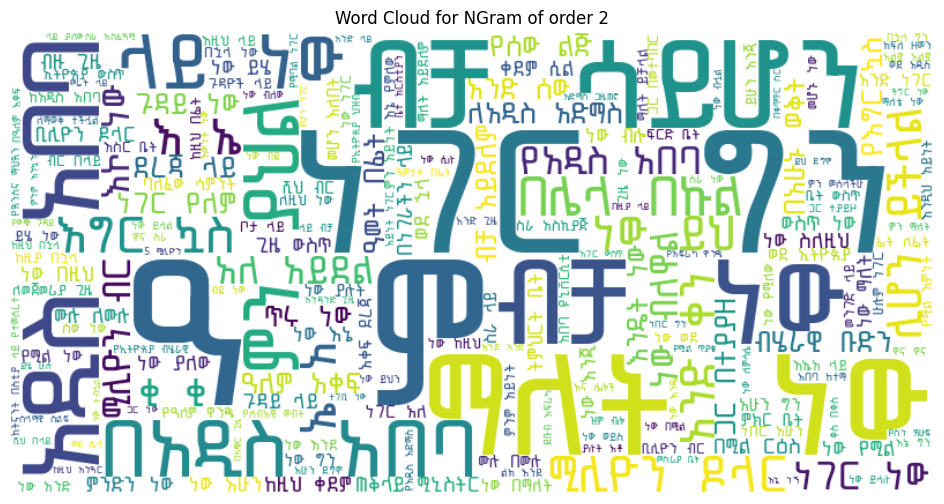

In [16]:
# DRAW BIGRAM WORDCLOUD
bigram.draw_wordcloud()

In [17]:
# BIGRAM SEQUENCE GENERATION
sentence = "የተጐናጸፉ ሰዎች የህይወት ታሪክ"
for i in range(15):
    top_suggestions = bigram.get_k_most_probable_words(sentence, k=1)
    if len(top_suggestions) > 0:
        sentence = sentence + " " + top_suggestions[0][0]
print(sentence)


የተጐናጸፉ ሰዎች የህይወት ታሪክ ነው ይህ ደግሞ ወደ ኋላ ላይ ነው ይህ ደግሞ ወደ ኋላ ላይ ነው ይህ ደግሞ


In [18]:
# REMOVE UNNEEDED MODEL AND CLEAN UP
del bigram
gc.collect()

2625

**INTRINSIC AND EXTRINSIC EVALUATION OF BIGRAM**

In [19]:
trained_bigram = NGramModel(train_data, n=2)

# BIGRAM PERPLEXITY CALCULATION (INTRINSIC EVALUATION)
perplexity = trained_bigram.calculate_perplexity(test_data)
print(f"Bigram gets a perplexity score of {perplexity}")

# BIGRAM ACCURACY CALCULATION (EXTRINSIC EVALUATION)
accuracy = trained_bigram.calculate_accuracy(test_data[-100:])
print(f"Bigram gets an accuracy score of {round(accuracy, 2)}%")

Initializing NGramModel instance of order 2...
Finished initializing NGramModel instance. Model is ready to use.
Bigram gets a perplexity score of 8.057218280128758
Bigram gets an accuracy score of 21.82%


In [20]:
# REMOVE UNNEEDED MODEL AND CLEAN UP
del trained_bigram
gc.collect()

0

# **TRIGRAM (NGRAM of order 3)**

In [21]:
# TRIGRAM (NGRAM OF ORDER 3)
trigram = NGramModel(corpus_words, 3)

Initializing NGramModel instance of order 3...
Finished initializing NGramModel instance. Model is ready to use.


In [22]:
# TRIGRAM TOP 10 MOST PROBABLE/FREQUENT SEQUENCES
trigram.get_k_most_frequent_sequences()

[('እ ኤ አ', 1506),
 ('ነው ነገር ግን', 683),
 ('ቂ ቂ ቂ', 638),
 ('ወደ አዲስ አበባ', 431),
 ('የኢትዮጵያ ብሄራዊ ቡድን', 416),
 ('ነበር ነገር ግን', 393),
 ('ከጊዜ ወደ ጊዜ', 364),
 ('ዓ ም ጀምሮ', 354),
 ('የአዲስ አድማስ ጋዜጠኛ', 345),
 ('እንግዲህ ጨዋታም አይደል', 339)]

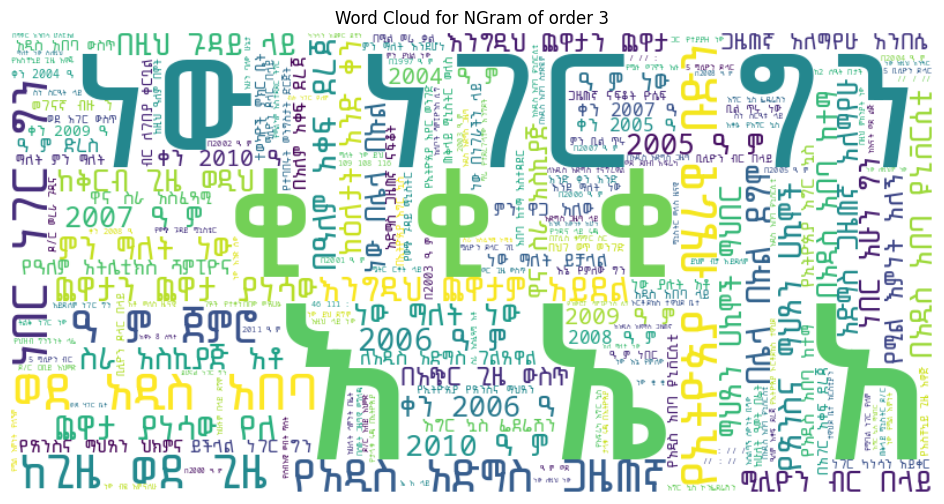

In [23]:
# DRAW TRIGRAM WORDCLOUD
trigram.draw_wordcloud()

In [24]:
# TRIGRAM SEQUENCE GENERATION
sentence = "የተጐናጸፉ ሰዎች የህይወት ታሪክ"
for i in range(15):
    top_suggestions = trigram.get_k_most_probable_words(sentence, k=1)
    if len(top_suggestions) > 0:
        sentence = sentence + " " + top_suggestions[0][0]
print(sentence)

የተጐናጸፉ ሰዎች የህይወት ታሪክ መጽሀፍ ውስጥ ስለ ኢትዮጵያ ታሪክ በሚለው መጽሀፋቸው ውስጥ ጥቂቱ ክፍል በፈጣሪው አንደበት ተነበበ በአቼቤ ልሳን


In [25]:
# REMOVE UNNEEDED MODEL AND CLEAN UP
del trigram
gc.collect()

2625

**INTRINSIC AND EXTRINSIC EVALUATION OF TRIGRAM**

In [26]:
trained_trigram = NGramModel(train_data, n=3)

# TRIGRAM PERPLEXITY CALCULATION (INTRINSIC EVALUATION)
perplexity = trained_trigram.calculate_perplexity(test_data)
print(f"Trigram gets a perplexity score of {perplexity}")

# TRIGRAM ACCURACY CALCULATION (EXTRINSIC EVALUATION)
accuracy = trained_trigram.calculate_accuracy(test_data[-100:])
print(f"Trigram gets an accuracy score of {round(accuracy, 2)}%")

Initializing NGramModel instance of order 3...
Finished initializing NGramModel instance. Model is ready to use.
Trigram gets a perplexity score of 1.539800810827849
Trigram gets an accuracy score of 22.96%


In [27]:
# REMOVE UNNEEDED MODEL AND CLEAN UP
del trained_trigram
gc.collect()

0

# **QUADRIGRAM (NGram of order 4)**

In [28]:
# QUADRIGRAM (NGRAM OF ORDER 3)
quadrigram = NGramModel(corpus_words, 4)

Initializing NGramModel instance of order 4...
Finished initializing NGramModel instance. Model is ready to use.


In [29]:
# QUADRIGRAM TOP 10 MOST PROBABLE/FREQUENT SEQUENCES
quadrigram.get_k_most_frequent_sequences()

[('ጨዋታን ጨዋታ ያነሳው የለ', 322),
 ('የጽንስና ማህጸን ሀኪሞች ማህበር', 242),
 ('ቀን 2006 ዓ ም', 219),
 ('እንግዲህ ጨዋታን ጨዋታ ያነሳው', 214),
 ('ቀን 2010 ዓ ም', 207),
 ('አድማስ ጋዜጠኛ አለማየሁ አንበሴ', 206),
 ('ቀን 2007 ዓ ም', 159),
 ('ቀን 2005 ዓ ም', 155),
 ('ቀን 2009 ዓ ም', 150),
 ('የአዲስ አድማስ ጋዜጠኛ አለማየሁ', 146)]

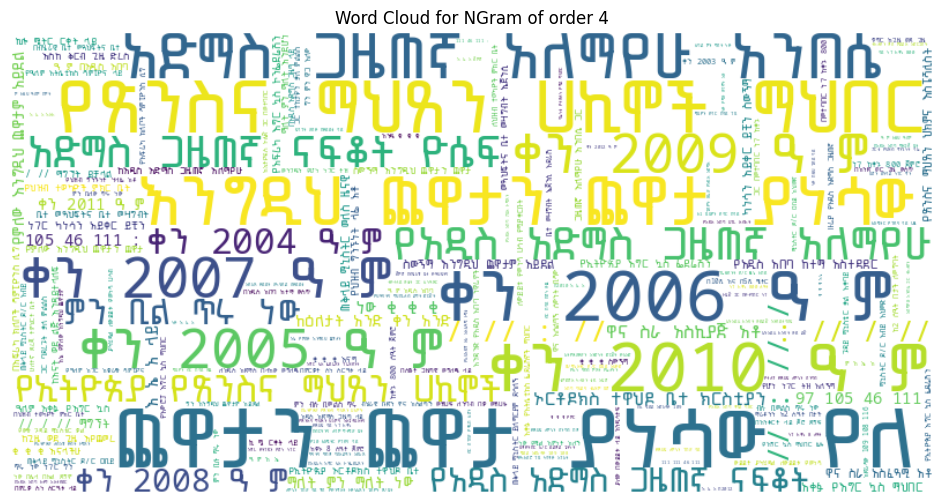

In [30]:
# DRAW QUADRIGRAM WORDCLOUD
quadrigram.draw_wordcloud()

In [31]:
# QUADRIGRAM SEQUENCE GENERATION
sentence = "የተጐናጸፉ ሰዎች የህይወት ታሪክ"
for i in range(15):
    top_suggestions = quadrigram.get_k_most_probable_words(sentence, k=1)
    if len(top_suggestions) > 0:
        sentence = sentence + " " + top_suggestions[0][0]
print(sentence)

የተጐናጸፉ ሰዎች የህይወት ታሪክ መመርመር ነው ያሉት ደግሞ በጠቅላይ ሚኒስቴር ሚኒስትር የኢትዮጵያ ፉትቦል ፌዴሬሽን አንደኛ ምክትል ፕሬዚዳንት የነበሩት አሁን


In [32]:
# REMOVE UNNEEDED MODEL AND CLEAN UP
del quadrigram
gc.collect()

2625

**INTRINSIC AND EXTRINSIC EVALUATION OF QUADRIGRAM**

In [33]:
trained_quadrigram = NGramModel(train_data, n=4)

# QUADRIGRAM PERPLEXITY CALCULATION (INTRINSIC EVALUATION)
perplexity = trained_quadrigram.calculate_perplexity(test_data)
print(f"Quadrigram gets a perplexity score of {perplexity}")

# QUADRIGRAM ACCURACY CALCULATION (EXTRINSIC EVALUATION)
accuracy = trained_quadrigram.calculate_accuracy(test_data[-100:])
print(f"Quadrigram gets an accuracy score of {round(accuracy, 2)}%")

Initializing NGramModel instance of order 4...
Finished initializing NGramModel instance. Model is ready to use.
Quadrigram gets a perplexity score of 1.170019189522718
Quadrigram gets an accuracy score of 3.61%


As can be seen, at n=4, the accuracy drops dramatically. This is because the number of possible unique 4-grams (4 word sequences) explodes exponentially. The training corpus becomes too small to contain most of the 4-gram sequences found in the test data.

In [34]:
# REMOVE UNNEEDED MODEL AND CLEAN UP
del trained_quadrigram
gc.collect()

0